## Identification results processing

JUMPlion takes a precursor-level identification report as one of its inputs and performs a series of steps to process the report for further analysis. These steps include:

1. Filtering precursors based on the number of runs in which they are identified
2. Building the RT/IM prediction model for each individual run and predicting RT/IM for precursors that are reported as missing
3. Selecting high-confidence precursors (based on precursor Q-value and the number of runs in which a precursor is identified) for mass calibration and IM window determination
4. Determining the number of data points to extract for an XIC based on RT prediction accuracy

The **precursor-level identification report** is a tabular file listing the identified precursors for each run, along with their retention time (RT), ion mobility (IM, for timsTOF data), and precursor-level Q-value. Supported file formats include .csv, .tsv, and .parquet. If using DIA-NN outputs, the report.parquet file can be used directly.

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# check the id report file
id_file = r"../tests/id_report_toy.parquet"
meta = pq.read_metadata(id_file)
schema = meta.schema.to_arrow_schema()
print(schema.names)

# read only required columns
is_tims = True
required_columns = ['Run', 'Precursor.Id', 'RT', 'Q.Value']
if is_tims:
    required_columns = required_columns + ['IM']
id_df = pd.read_parquet(id_file, columns=required_columns)

['Run', 'Precursor.Id', 'RT', 'Q.Value', 'IM']


In [2]:
id_df.head(12)

,Run,Precursor.Id,RT,Q.Value,IM
0,H6_3_D10_660,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,0.000875,1.014694
1,H6_4_D11_661,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.276978,0.000583,1.018494
2,H6_5_D12_662,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.211516,0.000520,1.014414
3,H6_6_E1_663,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.179474,0.000568,1.017563
4,H7_2_E4_666,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.163171,0.000815,1.026169
5,H7_3_E5_667,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.212599,0.002617,1.017643
6,H7_4_E6_668,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.197556,0.000728,1.021930
7,H7_5_E7_669,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.164258,0.000998,1.018805
8,H8_1_E10_672,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.181807,0.000593,1.024872
9,H8_2_E11_673,AAAAAAAAAAAPPAPPEGASPGDSAR3,14.180182,0.000512,1.025648


### 1. Select precursors for quantification
Related parameter: 
- **min_runs_quant**: The minimum number of runs in which a precursor must be identified to be considered for quantification.

In [3]:
min_runs_quant = 3
rt_mat = id_df.pivot(index='Precursor.Id', columns='Run', values='RT')
print(f"Before filtering: {len(rt_mat)} precursors")
rt_mat = rt_mat[(rt_mat.shape[1] - rt_mat.isna().sum(axis=1)) >= min_runs_quant]
print(f"After filtering: {len(rt_mat)} precursors")
print("RT matrix before prediction: ")
rt_mat.head(5)

Before filtering: 23465 precursors
After filtering: 23204 precursors
RT matrix before prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,14.276978,14.211516,14.179474,14.163171,14.212599,14.197556,14.164258,14.181807,14.180182,14.115888,14.181341
AAAADILPVLLK2,34.641689,34.642933,34.625931,34.592979,34.560818,34.498718,34.467770,34.530033,34.404064,34.386368,34.353931,34.324024
AAAEVLFRPNPHLLSEDR4,23.272438,23.305504,23.208574,23.271967,23.111540,23.113611,23.098444,23.080904,22.810789,22.825165,22.872595,22.778400
AAAGELQEDSGLC(UniMod:4)VLAR2,25.140625,25.221487,25.060736,25.156275,25.043690,25.029806,24.998707,25.029030,24.870806,24.853243,24.836758,24.822475
AAAGLGGGDSGDGTAR2,6.420696,6.438160,6.420632,6.388623,6.372499,NaN,NaN,6.405771,NaN,6.373291,6.389084,6.374893


In [4]:
im_mat = id_df.pivot(index='Precursor.Id', columns='Run', values='IM')
print(f"Before filtering: {len(im_mat)} precursors")
im_mat = im_mat[(im_mat.shape[1] - im_mat.isna().sum(axis=1)) >= min_runs_quant]
print(f"After filtering: {len(im_mat)} precursors")
print("IM matrix before prediction: ")
im_mat.head(5)

Before filtering: 23465 precursors
After filtering: 23204 precursors
IM matrix before prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,1.014694,1.018494,1.014414,1.017563,1.026169,1.017643,1.021930,1.018805,1.024872,1.025648,1.021247,1.022248
AAAADILPVLLK2,0.942524,0.943529,0.946151,0.948344,0.950000,0.950000,0.950000,0.948039,0.948750,0.947876,0.948927,0.946250
AAAEVLFRPNPHLLSEDR4,0.882500,0.883750,0.885000,0.885890,0.887500,0.888750,0.889672,0.888750,0.888545,0.886250,0.886542,0.886097
AAAGELQEDSGLC(UniMod:4)VLAR2,1.134687,1.135715,1.136372,1.139493,1.143611,1.144107,1.144044,1.144836,1.146402,1.145000,1.143605,1.142500
AAAGLGGGDSGDGTAR2,0.960000,0.961250,0.961034,0.960774,0.966340,NaN,NaN,0.965568,NaN,0.962019,0.966250,0.961566


### 2. RT/IM prediction
Related parameter: 
- **min_runs_model**: the minimum number of runs in which a precursor must be identified to be used for building the RT/IM prediction model.

Each precursor has an iRT value in the library. A model is built using the experimental RT and the library iRT. This model is then used to predict the experimental RT based on the iRT for precursors that lack an experimental RT. Similarly, the same approach can be applied to predict the experimental IM for precursors missing IM values.

The RT and IM prediction results are stored in the `intermediate/rt_prediction` and `intermediate/im_prediction` folders, respectively, in the output directory.

#### 2.1. Get iRT/iIM from the spectral library

In [5]:
min_runs_model = 3

from jumplion.id_results_processing import (collect_model_data, 
                                            modeling_and_prediction, 
                                            adjust_prediction_outliers)
from jumplion.calibration import (calc_spline, 
                                  refine_spline, 
                                  convert_to_arrays, 
                                  check_model_accuracy, 
                                  spline_fitting_plot)

# Read spectral library
lib_file = r"../tests/spectral_library_toy.parquet"
lib_df = pd.read_parquet(lib_file)

# Only use the iRT/iIM info in the library here
if is_tims:
    lib_df_uniq_prec = lib_df[['Precursor.Id', 'RT', 'IM', 'Precursor.Mz']].copy()
else:
    lib_df_uniq_prec = lib_df[['Precursor.Id', 'RT', 'Precursor.Mz']].copy()
lib_df_uniq_prec.drop_duplicates(subset=['Precursor.Id'], inplace=True, ignore_index=True)

#### 2.2. RT prediction

RT prediction model for run H6_3_D10_660:


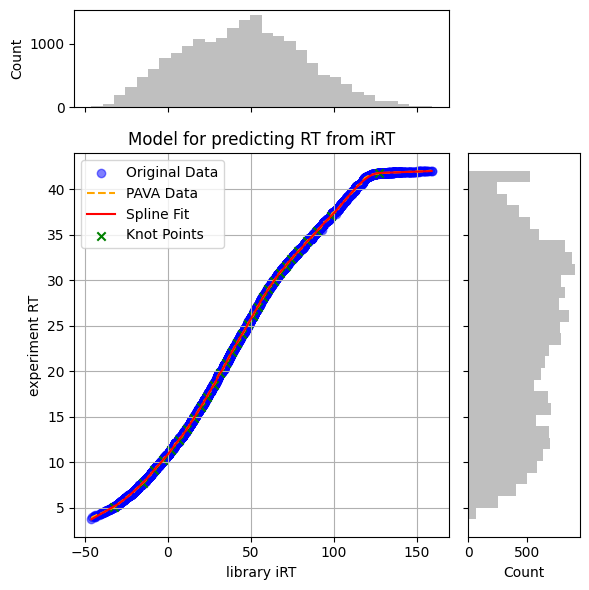

RT prediction accuracy for 80.0% precursors: 0.0578
Predicted experimental RT for iRT of 51.25 is 26.153.


In [6]:
# take one run as an example
run_name = 'H6_3_D10_660'

# Collect data
data_type="rt"
rt_dict, rt_segments = collect_model_data(rt_mat, min_runs_model, lib_df_uniq_prec, data_type)

# Modeling
delta_percentile = 0.8
model_data = rt_dict[run_name]
x, y = convert_to_arrays(model_data)
model_coeff, model_points = refine_spline(x, y, rt_segments)
model_acc = check_model_accuracy(model_data, model_coeff, model_points, delta_percentile)
print(f"{data_type.upper()} prediction model for run {run_name}:")
spline_fitting_plot(model_data, 
                    model_coeff, 
                    model_points, 
                    model_acc, 
                    show_window=False, 
                    model=data_type.upper(), 
                    out_dir="", 
                    run_name=run_name,
                    figsize=(6, 6),
                    save_plot=False)
print(f"{data_type.upper()} prediction accuracy for {delta_percentile * 100}% precursors: {np.round(model_acc, 4)}")

# prediction
lib_iRT = 51.25
predicted_rt = calc_spline(model_coeff, model_points, x=lib_iRT)
print(f"Predicted experimental RT for iRT of {lib_iRT} is {np.round(predicted_rt, 3)}.")

Average model accuracies: 0.05698 min (3.418934078117166 s)
RT matrix after prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,14.355443,14.276978,14.211516,14.179474,14.163171,14.212599,14.197556,14.164258,14.181807,14.180182,14.115888,14.181341
AAAADILPVLLK2,34.641689,34.642933,34.625931,34.592979,34.560818,34.498718,34.467770,34.530033,34.404064,34.386368,34.353931,34.324024
AAAEVLFRPNPHLLSEDR4,23.272438,23.305504,23.208574,23.271967,23.111540,23.113611,23.098444,23.080904,22.810789,22.825165,22.872595,22.778400
AAAGELQEDSGLC(UniMod:4)VLAR2,25.140625,25.221487,25.060736,25.156275,25.043690,25.029806,24.998707,25.029030,24.870806,24.853243,24.836758,24.822475
AAAGLGGGDSGDGTAR2,6.420696,6.438160,6.420632,6.388623,6.372499,6.357172,6.301412,6.405771,6.371650,6.373291,6.389084,6.374893


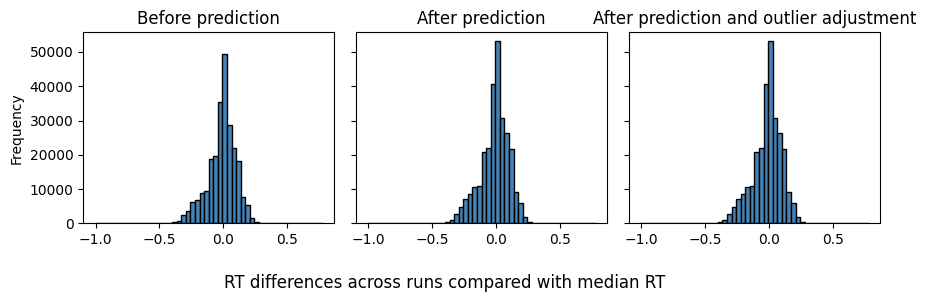

In [7]:
# Do the above for all runs
rt_mat_pred, rt_model_accs = modeling_and_prediction(rt_dict, rt_segments, rt_mat, 
                                                  lib_df_uniq_prec, data_type="rt", 
                                                  out_dir="", save_plot=False, 
                                                  save_model=False)
mean_rt_model_acc = np.mean(rt_model_accs)
print(f"Average model accuracies: {mean_rt_model_acc:.4g} min ({mean_rt_model_acc*60} s)")
# Adjust RT prediction outliers
rt_mat_pred = adjust_prediction_outliers(rt_mat_pred, rt_mat, 5, save_plot=False)
print("RT matrix after prediction: ")
rt_mat_pred.head(5)

#### 2.3. IM prediction

IM prediction model for run H6_3_D10_660:


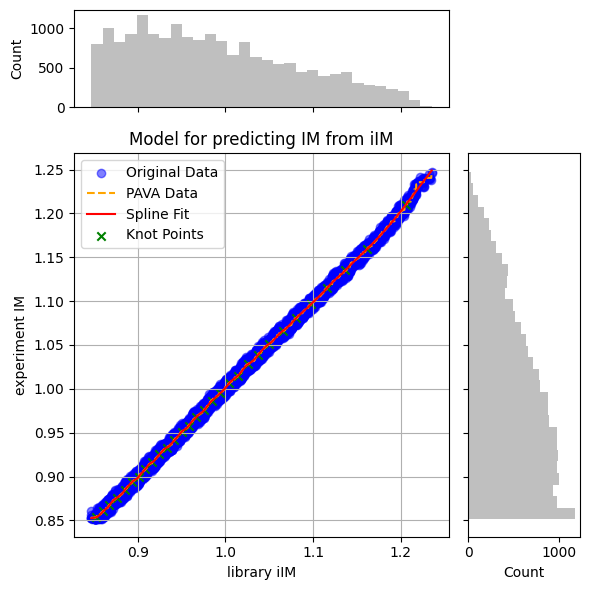

IM prediction accuracy for 80.0% precursors: 0.0037
Predicted experimental IM for iIM of 0.98 is 0.981.


In [8]:
# take one run as an example
run_name = 'H6_3_D10_660'

# Collect data
data_type="im"
im_dict, im_segments = collect_model_data(im_mat, min_runs_model, lib_df_uniq_prec, data_type)

# Modeling
delta_percentile = 0.8
model_data = im_dict[run_name]
x, y = convert_to_arrays(model_data)
model_coeff, model_points = refine_spline(x, y, rt_segments)
model_acc = check_model_accuracy(model_data, model_coeff, model_points, delta_percentile)
print(f"{data_type.upper()} prediction model for run {run_name}:")
spline_fitting_plot(model_data, 
                    model_coeff, 
                    model_points, 
                    model_acc, 
                    show_window=False, 
                    model=data_type.upper(), 
                    out_dir="", 
                    run_name=run_name,
                    figsize=(6, 6),
                    save_plot=False)
print(f"{data_type.upper()} prediction accuracy for {delta_percentile * 100}% precursors: {np.round(model_acc, 4)}")

# prediction
lib_iIM = 0.98
predicted_im = calc_spline(model_coeff, model_points, x=lib_iIM)
print(f"Predicted experimental IM for iIM of {lib_iIM} is {np.round(predicted_im, 3)}.")

In [9]:
# Do the above for all runs
im_mat_pred, im_model_accs = modeling_and_prediction(im_dict, im_segments, im_mat, 
                                                  lib_df_uniq_prec, data_type="im", 
                                                  out_dir="", save_plot=False, 
                                                  save_model=False)
mean_im_model_acc = np.mean(im_model_accs)
print(f"Average model accuracies: {mean_im_model_acc:.4g}")
print("IM matrix after prediction: ")
im_mat_pred.head(5)

Average model accuracies: 0.003522
IM matrix after prediction: 


Run,H6_3_D10_660,H6_4_D11_661,H6_5_D12_662,H6_6_E1_663,H7_2_E4_666,H7_3_E5_667,H7_4_E6_668,H7_5_E7_669,H8_1_E10_672,H8_2_E11_673,H8_3_E12_674,H8_4_F1_675
Precursor.Id,,,,,,,,,,,,
AAAAAAAAAAAPPAPPEGASPGDSAR3,1.014694,1.018494,1.014414,1.017563,1.026169,1.017643,1.021930,1.018805,1.024872,1.025648,1.021247,1.022248
AAAADILPVLLK2,0.942524,0.943529,0.946151,0.948344,0.950000,0.950000,0.950000,0.948039,0.948750,0.947876,0.948927,0.946250
AAAEVLFRPNPHLLSEDR4,0.882500,0.883750,0.885000,0.885890,0.887500,0.888750,0.889672,0.888750,0.888545,0.886250,0.886542,0.886097
AAAGELQEDSGLC(UniMod:4)VLAR2,1.134687,1.135715,1.136372,1.139493,1.143611,1.144107,1.144044,1.144836,1.146402,1.145000,1.143605,1.142500
AAAGLGGGDSGDGTAR2,0.960000,0.961250,0.961034,0.960774,0.966340,0.965850,0.965897,0.965568,0.965697,0.962019,0.966250,0.961566


### 3. Select high-confidence precursors for mass calibration and IM window determination
Related parameters: 
- **max_qvalue_cal**: Maximum q-value (FDR) for a precursor to be used for mass calibration.
- **min_runs_cal**: Minimum number of runs in which a precursor must be identified to be used for mass calibration.
- **max_mass_cal**: Maximum number of precursors used for mass calibration.

To select precursors for mass calibration, we aim to include those that can be confidently identified in the majority of runs.

In [10]:
max_qvalue_cal = 1e-4
min_runs_cal = 6
max_mass_cal = 5000

id_df_cal = id_df.loc[id_df['Q.Value'] < max_qvalue_cal, ['Precursor.Id', 'Run', 'Q.Value']]
q_mat_cal = id_df_cal.pivot(index='Precursor.Id', columns='Run', values='Q.Value')
q_mat_cal = q_mat_cal[(q_mat_cal.shape[1] - q_mat_cal.isna().sum(axis=1)) >= min_runs_cal]
print(f"{len(q_mat_cal)} precursors with Q-values < {max_qvalue_cal} are detected in at least (>=) {min_runs_cal} runs")
q_means = q_mat_cal.mean(axis=1, numeric_only=True)
mass_cal_precs = q_means.nsmallest(max_mass_cal).index.values
print(f"The top {len(mass_cal_precs)} (ordered by average Q-value) of them are selected for mass calibration\n")

7072 precursors with Q-values < 0.0001 are detected in at least (>=) 6 runs
The top 5000 (ordered by average Q-value) of them are selected for mass calibration



### 4. Determining the number of data points to extract for an XIC

Related parameter: 
- **nXICPoints**: Number of data points to extract for each XIC.

The RT extraction window is determined from the RT prediction accuracy. The prediction accuracy is converted to the number of data points (`mean_rt_model_acc_n_points`) by dividing it by the cycle time. The minimum RT range is then calculated as `mean_rt_model_acc_n_points * 4 + 1`. If this value is smaller than `nXICPoints`, `nXICPoints` is used.

In [11]:
nXICPoints = 20

cycle_time = 0.016 # min
print(f"Cycle time: {cycle_time} ({np.round(cycle_time*60, 3)} seconds)")
 
mean_rt_model_acc_n_points = int(np.round(mean_rt_model_acc / cycle_time))
print(f"Average RT prediction accuracy in terms of the number of data points in XICs: {mean_rt_model_acc_n_points}")

n_xic_points = max(nXICPoints, mean_rt_model_acc_n_points * 4 + 1)
print(f"Number of data points to extract for a XIC set to: {n_xic_points}\n")

Cycle time: 0.016 (0.96 seconds)
Average RT prediction accuracy in terms of the number of data points in XICs: 4
Number of data points to extract for a XIC set to: 20

